In [59]:
import numpy as np
import pandas as pd
# дописываем библиотеки
import matplotlib.pyplot as plt
import seaborn as sns



In [60]:
# задание 1 балл (сум 1)
# загрузить данные, индекс переменная вида дата/время
crime = pd.read_csv('/Users/sofkatulyakova/Downloads/crime.csv.zip')
crime['datetime'] = pd.to_datetime(crime.iloc[:, 0])  # первый столбец содержит дату
crime['year'] = crime['datetime'].dt.year
crime['month'] = crime['datetime'].dt.month
crime['day'] = crime['datetime'].dt.day

# и срезать данные за 2010-2013 год
crime_2010_2013 = crime[(crime['year'] >= 2010) & (crime['year'] <= 2013)]
crime_2010_2013
# в дальнейшем использовать ТОЛЬКО срезанные данные


,Unnamed: 0,id,state,location_raw,county_name,county_fips,fine_grained_location,police_department,driver_gender,driver_age_raw,...,search_type_raw,search_type,contraband_found,stop_outcome,is_arrested,officer_id,datetime,year,month,day
0,2010-07-01 00:10,VT-2010-00001,VT,East Montpelier,Washington County,50023.0,COUNTY RD,MIDDLESEX VSP,M,22.0,...,No Search Conducted,NaN,False,Citation,False,-1.562157e+09,2010-07-01 00:10:00,2010,7,1
1,2010-07-01 00:11,VT-2010-00004,VT,Whiting,Addison County,50001.0,N MAIN ST,NEW HAVEN VSP,F,18.0,...,No Search Conducted,NaN,False,Arrest for Violation,True,-3.126844e+08,2010-07-01 00:11:00,2010,7,1
2,2010-07-01 00:35,VT-2010-00005,VT,Hardwick,Caledonia County,50005.0,i91 nb mm 62,ROYALTON VSP,M,18.0,...,No Search Conducted,NaN,False,Written Warning,False,9.225661e+08,2010-07-01 00:35:00,2010,7,1
3,2010-07-01 00:44,VT-2010-00006,VT,Hardwick,Caledonia County,50005.0,64000 I 91 N; MM64 I 91 N,ROYALTON VSP,F,20.0,...,No Search Conducted,NaN,False,Written Warning,False,-6.032327e+08,2010-07-01 00:44:00,2010,7,1
4,2010-07-01 01:10,VT-2010-00009,VT,Rochester,Windsor County,50027.0,36000 I 91 S; MM36 I 91 S,ROCKINGHAM VSP,M,24.0,...,No Search Conducted,NaN,False,Written Warning,False,2.939526e+08,2010-07-01 01:10:00,2010,7,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176171,2013-12-31 23:40,VT-2013-57230,VT,Brattleboro,Windham County,50025.0,485 W RIVER RD,BRATTLEBORO VSP,M,32.0,...,No Search Conducted,NaN,False,Written Warning,False,1.176168e+09,2013-12-31 23:40:00,2013,12,31
176172,2013-12-31 23:45,VT-2013-57231,VT,Charleston,Orleans County,50019.0,VT RT 105 & SCHOOL,DERBY VSP,M,20.0,...,No Search Conducted,NaN,False,Written Warning,False,-1.794069e+09,2013-12-31 23:45:00,2013,12,31
176173,2013-12-31 23:45,VT-2013-57232,VT,Bristol,Addison County,50001.0,Burpee Road,NEW HAVEN VSP,M,54.0,...,No Search Conducted,NaN,False,Written Warning,False,-4.360221e+08,2013-12-31 23:45:00,2013,12,31
176174,2013-12-31 23:50,VT-2013-57233,VT,Saint Johnsbury,Caledonia County,50005.0,Memorial Dr,ST JOHNSBURY VSP,F,27.0,...,No Search Conducted,NaN,False,Written Warning,False,-5.082475e+08,2013-12-31 23:50:00,2013,12,31


In [61]:
# задание 1 балл (сум 2)
# построить сводную таблицу по клоличеству 
# правонарушений в зависимости от пола (driver_gender)- строки 
# и типа правонарушения (violation) - колонки
# ВНИМАНИЕ! NaN должен быть заменен на 0

pivot_table = pd.pivot_table(
    data=crime_2010_2013,
    index='driver_gender',     
    columns='violation',        
    aggfunc='size',            
    fill_value=0                
)


print(pivot_table)

violation      DUI  Equipment  Moving violation  Other  Other (non-mapped)
driver_gender                                                             
F              136      12055             49876   2047                   0
M              364      20154             87846   3697                   1


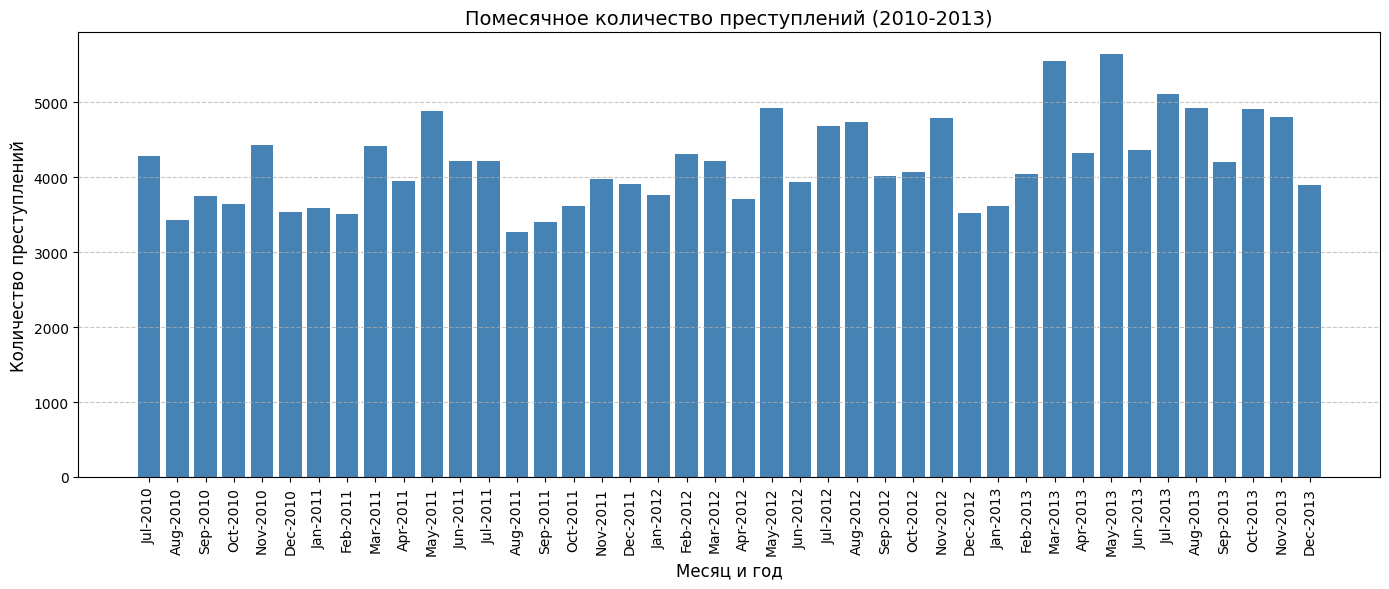

In [62]:
# задание 2 балла (сум 4)
# найти помесячное количество преступлений и постройте столбцовый график
# сделайте правильно :)
monthly_crimes = crime_2010_2013.groupby(['year', 'month']).size().reset_index(name='count')

monthly_crimes['month_year'] = pd.to_datetime(
    monthly_crimes['year'].astype(str) + '-' + 
    monthly_crimes['month'].astype(str)
).dt.strftime('%b-%Y')

# график
plt.figure(figsize=(14, 6))
plt.bar(monthly_crimes['month_year'], monthly_crimes['count'], color='steelblue')

# оформление
plt.title('Помесячное количество преступлений (2010-2013)', fontsize=14)
plt.xlabel('Месяц и год', fontsize=12)
plt.ylabel('Количество преступлений', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



/var/folders/wz/7gxs93rj2710v6r1rv_dzzdw0000gn/T/ipykernel_69902/4282479476.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  crime_2010_2013['day_of_week'] = crime_2010_2013['datetime'].dt.dayofweek


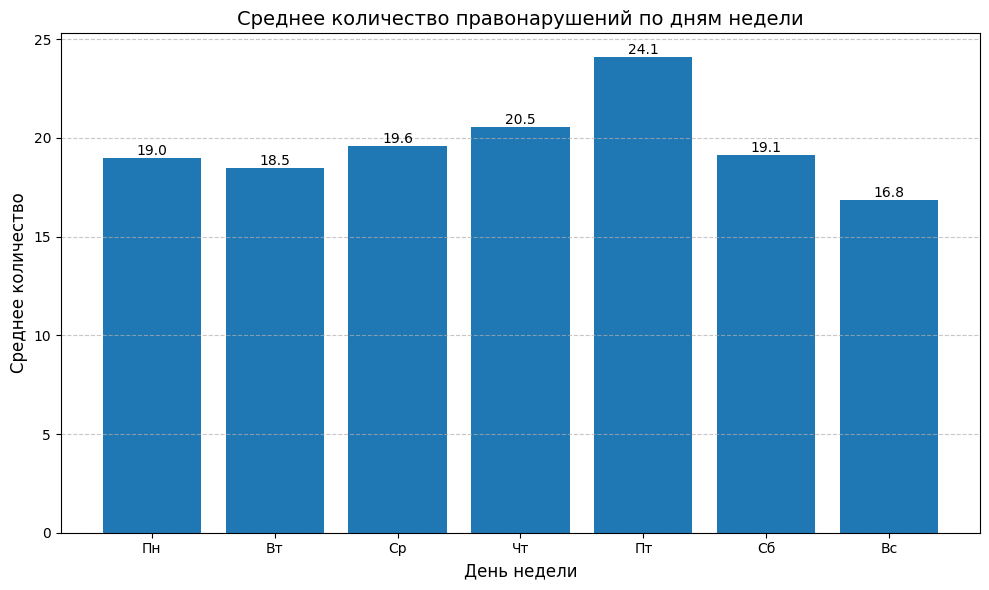

In [63]:
# задание 2 балла (сум 6)
# найти ежедневное количество правонарушений и найти среднее количество 
# правонарушений в зависимости от дня недели, визуализировать этот результат столбцовой диаграммой
# корректно подписать столбцы Пн-Вс, за цифры на оси x снижу балл

daily_crimes = crime_2010_2013.groupby(crime_2010_2013['datetime'].dt.date).size().reset_index(name='count')

# (0-понедельник, 6-воскресенье)
crime_2010_2013['day_of_week'] = crime_2010_2013['datetime'].dt.dayofweek

weekday_avg = crime_2010_2013.groupby('day_of_week').size() / crime_2010_2013['datetime'].dt.date.nunique()
weekday_avg = weekday_avg.reset_index(name='average')

weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_avg['day_name'] = weekday_avg['day_of_week'].apply(lambda x: weekday_names[x])

weekday_avg = weekday_avg.sort_values('day_of_week')

# график
plt.figure(figsize=(10, 6))
bars = plt.bar(weekday_avg['day_name'], weekday_avg['average'], color='#1f77b4')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f}',
             ha='center', va='bottom')


plt.title('Среднее количество правонарушений по дням недели', fontsize=14)
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Среднее количество', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


Статистика по DUI:
  day_name  count  normalized
5       Сб    138    0.563702
6       Вс     90    0.417498
4       Пт     91    0.295129
2       Ср     50    0.199681
1       Вт     44    0.185968
0       Пн     45    0.184995
3       Чт     42    0.159823


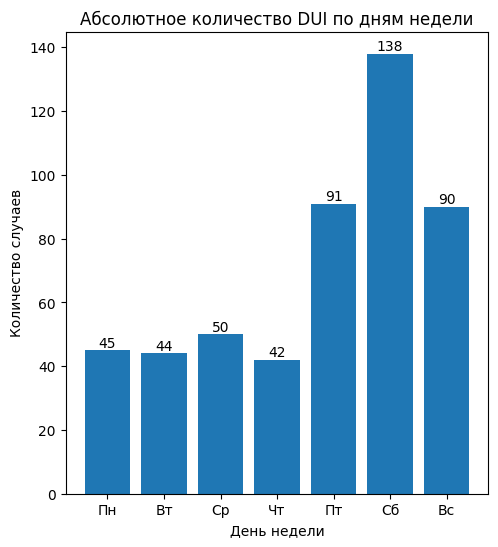

In [65]:
# задание 2 балла (сум 8)
# отобрать волителей под веществами violation -> DUI (Driving under the influence)
# существует ли зависимость на наборе данных водителей DUI от дня недели и какая? 
# построить график и описать зависимость.

dui_cases = crime_2010_2013[crime_2010_2013['violation'] == 'DUI'].copy()
# (0-понедельник, 6-воскресенье)
dui_cases['day_of_week'] = dui_cases['datetime'].dt.dayofweek

weekday_dui = dui_cases.groupby('day_of_week').size().reset_index(name='count')

weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_dui['day_name'] = weekday_dui['day_of_week'].map(lambda x: weekday_names[x])


total_by_weekday = crime_2010_2013.groupby(crime['datetime'].dt.dayofweek).size()
weekday_dui['normalized'] = weekday_dui['count'] / total_by_weekday * 100 

# график 
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
bars = plt.bar(weekday_dui['day_name'], weekday_dui['count'])
plt.title('Абсолютное количество DUI по дням недели')
plt.xlabel('День недели')
plt.ylabel('Количество случаев')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             int(height),
             ha='center', va='bottom')

# статистика
print("\nСтатистика по DUI:")
print(weekday_dui[['day_name', 'count', 'normalized']].sort_values('normalized', ascending=False))


Самый 'пьяный' день недели: Сб
Самый 'пьяный' час: 23:00-24:00
Количество случаев в этот час: 21


/var/folders/wz/7gxs93rj2710v6r1rv_dzzdw0000gn/T/ipykernel_69902/3038855160.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  most_drunk_day_cases['hour'] = most_drunk_day_cases['datetime'].dt.hour


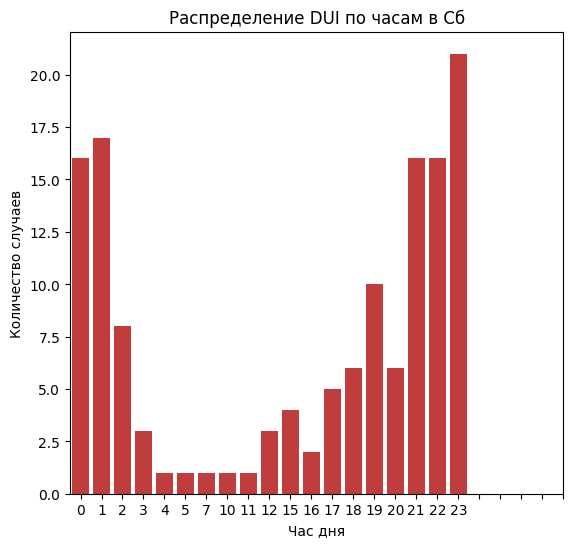

In [66]:
# задание 2 балла (сум 10)
# для самого "пьяного дня" найти самый "пьяный час"
# визулализировать для подтверждения 
dui_by_weekday = dui_cases['datetime'].dt.dayofweek.value_counts().sort_index()
most_drunk_day = dui_by_weekday.idxmax()
day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
most_drunk_day_name = day_names[most_drunk_day]

most_drunk_day_cases = dui_cases[dui_cases['datetime'].dt.dayofweek == most_drunk_day]

most_drunk_day_cases['hour'] = most_drunk_day_cases['datetime'].dt.hour
hourly_distribution = most_drunk_day_cases['hour'].value_counts().sort_index()

# график
plt.figure(figsize=(14, 6))

# График распределения по часам
plt.subplot(1, 2, 1)
sns.barplot(x=hourly_distribution.index, y=hourly_distribution.values, color='#d62728')
plt.title(f'Распределение DUI по часам в {most_drunk_day_name}')
plt.xlabel('Час дня')
plt.ylabel('Количество случаев')
plt.xticks(range(0, 24))


most_drunk_hour = hourly_distribution.idxmax()
print(f"\nСамый 'пьяный' день недели: {most_drunk_day_name}")
print(f"Самый 'пьяный' час: {most_drunk_hour}:00-{most_drunk_hour+1}:00")
print(f"Количество случаев в этот час: {hourly_distribution.max()}")
